<a href="https://colab.research.google.com/github/nhimsonitaa-bot/Spotify_Olist_EDA_Analysis/blob/main/Spotify_Olist_EDA_Analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Pandas 기반 탐색적 데이터 분석(EDA) 보고서
## Spotify Songs Dataset & Brazilian E-Commerce (Olist) Dataset


## 0. 라이브러리 불러오기 및 데이터 파일 경로 설정

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
import warnings

warnings.filterwarnings("ignore")
pd.set_option("display.max_columns", 50)
pd.set_option("display.max_rows", 100)
sns.set_theme(style="whitegrid")

# CSV 파일을 노트북과 같은 폴더에 두는 것을 권장합니다.
DATA_DIR = Path(".")

# Spotify Kaggle 파일명은 보통 dataset.csv 입니다.
SPOTIFY_FILE = DATA_DIR / "dataset.csv"

# Olist 표준 파일명
ORDERS_FILE = DATA_DIR / "olist_orders_dataset.csv"
PAYMENTS_FILE = DATA_DIR / "olist_order_payments_dataset.csv"
CUSTOMERS_FILE = DATA_DIR / "olist_customers_dataset.csv"
REVIEWS_FILE = DATA_DIR / "olist_order_reviews_dataset.csv"

print("현재 작업 폴더:", Path.cwd())

# 1. Spotify Songs Dataset 분석

## 1.1 데이터 불러오기 및 구조 확인
Spotify 데이터에는 트랙명, 아티스트, 장르, 인기도(popularity), danceability, energy, valence 등의 변수가 포함되어 있다.

In [2]:
import os

print(os.listdir())

['.config', 'olist_customers_dataset.csv', 'olist_geolocation_dataset.csv', 'olist_products_dataset.csv', 'olist_order_payments_dataset.csv', 'olist_sellers_dataset.csv', 'product_category_name_translation.csv', 'olist_orders_dataset.csv', 'olist_order_items_dataset.csv', 'dataset.csv', 'olist_order_reviews_dataset.csv', 'sample_data']


In [3]:
SPOTIFY_FILE = "dataset.csv"

In [5]:
import pandas as pd

spotify = pd.read_csv("/content/dataset.csv")

print("데이터 크기:", spotify.shape)

display(spotify.head())

spotify.info()

데이터 크기: (114000, 21)


,Unnamed: 0,track_id,artists,album_name,track_name,popularity,duration_ms,explicit,danceability,energy,...,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,track_genre
0,0,5SuOikwiRyPMVoIQDJUgSV,Gen Hoshino,Comedy,Comedy,73,230666,False,0.676,0.4610,...,-6.746,0,0.1430,0.0322,0.000001,0.3580,0.715,87.917,4,acoustic
1,1,4qPNDBW1i3p13qLCt0Ki3A,Ben Woodward,Ghost (Acoustic),Ghost - Acoustic,55,149610,False,0.420,0.1660,...,-17.235,1,0.0763,0.9240,0.000006,0.1010,0.267,77.489,4,acoustic
2,2,1iJBSr7s7jYXzM8EGcbK5b,Ingrid Michaelson;ZAYN,To Begin Again,To Begin Again,57,210826,False,0.438,0.3590,...,-9.734,1,0.0557,0.2100,0.000000,0.1170,0.120,76.332,4,acoustic
3,3,6lfxq3CG4xtTiEg7opyCyx,Kina Grannis,Crazy Rich Asians (Original Motion Picture Sou...,Can't Help Falling In Love,71,201933,False,0.266,0.0596,...,-18.515,1,0.0363,0.9050,0.000071,0.1320,0.143,181.740,3,acoustic
4,4,5vjLSffimiIP26QG5WcN2K,Chord Overstreet,Hold On,Hold On,82,198853,False,0.618,0.4430,...,-9.681,1,0.0526,0.4690,0.000000,0.0829,0.167,119.949,4,acoustic


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 114000 entries, 0 to 113999
Data columns (total 21 columns):
 #   Column            Non-Null Count   Dtype  
---  ------            --------------   -----  
 0   Unnamed: 0        114000 non-null  int64  
 1   track_id          114000 non-null  object 
 2   artists           113999 non-null  object 
 3   album_name        113999 non-null  object 
 4   track_name        113999 non-null  object 
 5   popularity        114000 non-null  int64  
 6   duration_ms       114000 non-null  int64  
 7   explicit          114000 non-null  bool   
 8   danceability      114000 non-null  float64
 9   energy            114000 non-null  float64
 10  key               114000 non-null  int64  
 11  loudness          114000 non-null  float64
 12  mode              114000 non-null  int64  
 13  speechiness       114000 non-null  float64
 14  acousticness      114000 non-null  float64
 15  instrumentalness  114000 non-null  float64
 16  liveness          11

## 1.2 결측치 및 데이터 품질 확인

전체 결측치와 분석에 필요한 주요 수치형 변수의 결측치를 확인한다. 보고서에서는 전체 결측 셀이 3개이며, popularity, danceability, energy, valence에는 결측치가 없었다.

In [6]:
missing_counts = spotify.isna().sum()
missing_summary = missing_counts[missing_counts > 0].sort_values(ascending=False)
print("결측치가 있는 컬럼:")
display(missing_summary)

required_cols = ["popularity", "danceability", "energy", "valence"]
for col in required_cols:
    if col in spotify.columns:
        spotify[col] = pd.to_numeric(spotify[col], errors="coerce")

print("주요 분석 변수 결측치:")
display(spotify[required_cols].isna().sum())

결측치가 있는 컬럼:


,0
artists,1
album_name,1
track_name,1


주요 분석 변수 결측치:


,0
popularity,0
danceability,0
energy,0
valence,0


## 1.3 인기도(popularity) 기초 통계

인기도의 평균, 중앙값, 표준편차, 최솟값, 최댓값을 계산한다. 보고서 기준 결과는 평균 33.24, 중앙값 35, 표준편차 22.31, 최솟값 0, 최댓값 100이다.

In [7]:
popularity_stats = spotify["popularity"].describe()
display(popularity_stats)

print("평균:", round(spotify["popularity"].mean(), 2))
print("중앙값:", spotify["popularity"].median())
print("표준편차:", round(spotify["popularity"].std(), 2))
print("최솟값:", spotify["popularity"].min())
print("최댓값:", spotify["popularity"].max())

,popularity
count,114000.000000
mean,33.238535
std,22.305078
min,0.000000
25%,17.000000
50%,35.000000
75%,50.000000
max,100.000000


평균: 33.24
중앙값: 35.0
표준편차: 22.31
최솟값: 0
최댓값: 100


## 1.4 인기도 80 이상 트랙 필터링 및 장르별 분포

인기도가 80 이상인 트랙을 추출하고 장르별 행 개수를 계산한다. 하나의 곡이 여러 장르 레이블에 나타날 수 있으므로 결과는 고유 곡 수가 아닌 장르가 부여된 행 수로 해석한다.

In [9]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

인기도 80 이상 트랙 행 수: 1201
해당 행에 포함된 장르 수: 65


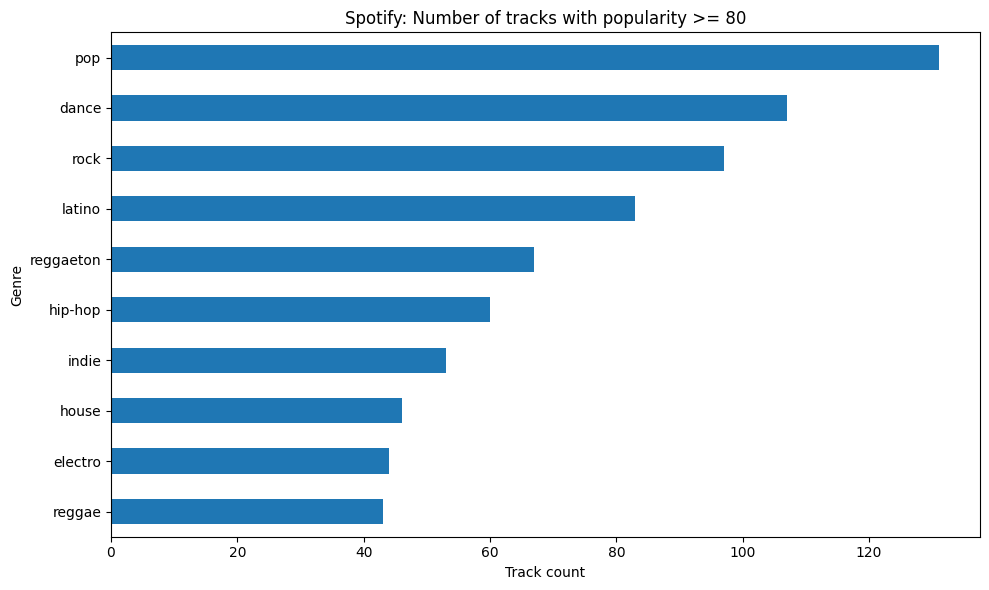

,count
track_genre,
pop,131
dance,107
rock,97
latino,83
reggaeton,67
hip-hop,60
indie,53
house,46
electro,44


In [10]:
popular_tracks = spotify.loc[spotify["popularity"] >= 80].copy()
print("인기도 80 이상 트랙 행 수:", len(popular_tracks))
print("해당 행에 포함된 장르 수:", popular_tracks["track_genre"].nunique())

genre_popular_counts = (
    popular_tracks["track_genre"]
    .value_counts()
    .head(10)
    .sort_values()
)

plt.figure(figsize=(10, 6))
genre_popular_counts.plot(kind="barh")
plt.title("Spotify: Number of tracks with popularity >= 80")
plt.xlabel("Track count")
plt.ylabel("Genre")
plt.tight_layout()
plt.show()

display(genre_popular_counts.sort_values(ascending=False))

### 해석 및 인사이트
보고서에서는 인기도 80 이상인 트랙 행이 1,201개이며, 65개 장르에 분포한다고 정리했다. 장르별로는 pop, dance, rock, latino, reggaeton 순으로 많이 나타났다. 이는 해당 데이터셋에서 높은 인기도를 기록한 트랙이 이 장르들에 상대적으로 많이 분포한다는 점을 보여준다. 다만 장르별 데이터 수와 중복 장르 레이블의 영향을 고려해야 한다.

## 1.5 인기도 80 이상 상위 곡 확인

인기도 기준으로 정렬하고, 곡명과 아티스트가 같은 중복 행은 제거하여 상위 곡을 확인한다.

In [11]:
top_popular_tracks = (
    popular_tracks
    .sort_values("popularity", ascending=False)
    .drop_duplicates(subset=["track_name", "artists"])
)

display(top_popular_tracks[
    ["track_name", "artists", "track_genre", "popularity"]
].head(10))

,track_name,artists,track_genre,popularity
20001,Unholy (feat. Kim Petras),Sam Smith;Kim Petras,dance,100
51664,"Quevedo: Bzrp Music Sessions, Vol. 52",Bizarrap;Quevedo,hip-hop,99
68303,La Bachata,Manuel Turizo,latino,98
30003,I'm Good (Blue),David Guetta;Bebe Rexha,edm,98
67359,Tití Me Preguntó,Bad Bunny,latin,97
67358,Me Porto Bonito,Bad Bunny;Chencho Corleone,latin,97
91003,I Ain't Worried,OneRepublic,rock,96
20000,Under The Influence,Chris Brown,dance,96
68359,Efecto,Bad Bunny,latino,96
81052,As It Was,Harry Styles,pop,95


## 1.6 장르별 danceability 및 energy 평균 비교

장르별 평균 danceability와 energy를 계산한다. 보고서에서는 평균 energy가 높은 상위 8개 장르를 비교했다.

,danceability,energy
track_genre,,
death-metal,0.368411,0.931470
grindcore,0.271854,0.924201
metalcore,0.423800,0.914485
happy,0.552847,0.910971
hardstyle,0.539229,0.901246
drum-and-bass,0.535486,0.876635
black-metal,0.296411,0.874897
heavy-metal,0.428500,0.874003


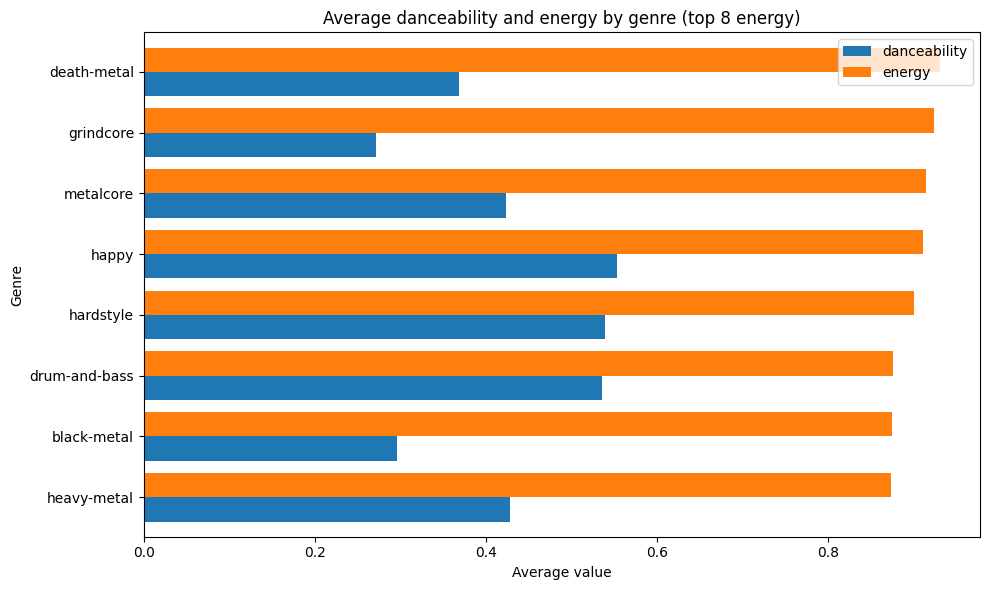

In [12]:
genre_audio = (
    spotify.groupby("track_genre")[["danceability", "energy"]]
    .mean()
    .sort_values("energy", ascending=False)
    .head(8)
)

display(genre_audio)

ax = genre_audio.sort_values("energy").plot(
    kind="barh", figsize=(10, 6), width=0.8
)
ax.set_title("Average danceability and energy by genre (top 8 energy)")
ax.set_xlabel("Average value")
ax.set_ylabel("Genre")
plt.tight_layout()
plt.show()

### 해석 및 인사이트
Energy는 음악의 강도와 활동성을 나타내고, danceability는 리듬과 템포 등의 특성을 바탕으로 춤추기 쉬운 정도를 나타낸다. 두 지표는 서로 다른 특성이므로 장르별 평균에 차이가 나타날 수 있다. 특정 장르의 에너지가 높다고 해서 반드시 댄스성도 가장 높은 것은 아니다.

## 1.7 valence와 popularity의 상관관계

두 변수의 피어슨 상관계수를 계산하고 산점도로 관계를 확인한다. 그래프는 데이터가 많으므로 최대 5,000개 행을 무작위 표본으로 표시한다.

valence와 popularity의 피어슨 상관계수: -0.041


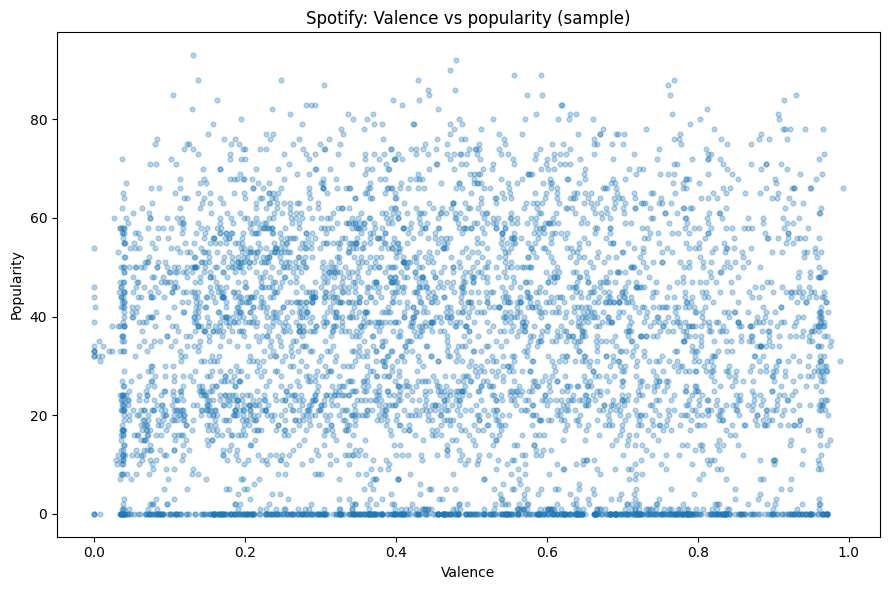

In [13]:
correlation = spotify[["valence", "popularity"]].corr().iloc[0, 1]
print("valence와 popularity의 피어슨 상관계수:", round(correlation, 3))

sample_n = min(5000, len(spotify))
spotify_sample = spotify[["valence", "popularity"]].dropna().sample(
    n=min(sample_n, len(spotify[["valence", "popularity"]].dropna())),
    random_state=42
)

plt.figure(figsize=(9, 6))
plt.scatter(
    spotify_sample["valence"],
    spotify_sample["popularity"],
    alpha=0.3,
    s=12
)
plt.title("Spotify: Valence vs popularity (sample)")
plt.xlabel("Valence")
plt.ylabel("Popularity")
plt.tight_layout()
plt.show()

### 해석 및 인사이트
보고서에서 계산한 피어슨 상관계수는 약 -0.041이다. 절댓값이 매우 작으므로 두 변수 사이에 뚜렷한 선형 관계가 거의 관찰되지 않는다. 따라서 곡의 밝기만으로 인기도를 설명하기 어렵고, 아티스트 인지도, 발매 시점, 홍보, 장르 등 다른 요인도 함께 고려해야 한다.

# 2. Brazilian E-Commerce (Olist) Dataset 분석

## 2.1 데이터 불러오기 및 구조 확인
Olist 분석에서는 주문, 결제, 고객, 리뷰 테이블을 사용한다. 결제 테이블은 한 주문에 여러 결제 행이 있을 수 있으므로 주문별 결제액을 먼저 합산한 뒤 병합한다.

In [14]:
orders = pd.read_csv(ORDERS_FILE)
payments = pd.read_csv(PAYMENTS_FILE)
customers = pd.read_csv(CUSTOMERS_FILE)
reviews = pd.read_csv(REVIEWS_FILE)

print("주문 데이터:", orders.shape)
print("결제 데이터:", payments.shape)
print("고객 데이터:", customers.shape)
print("리뷰 데이터:", reviews.shape)

display(orders.head())
display(payments.head())
display(customers.head())
display(reviews.head())

NameError: name 'ORDERS_FILE' is not defined

In [16]:
ORDERS_FILE = "/content/olist_orders_dataset.csv"
PAYMENTS_FILE = "/content/olist_order_payments_dataset.csv"
CUSTOMERS_FILE = "/content/olist_customers_dataset.csv"
REVIEWS_FILE = "/content/olist_order_reviews_dataset.csv"

orders = pd.read_csv(ORDERS_FILE)
payments = pd.read_csv(PAYMENTS_FILE)
customers = pd.read_csv(CUSTOMERS_FILE)
reviews = pd.read_csv(REVIEWS_FILE)

print("주문 데이터:", orders.shape)
print("결제 데이터:", payments.shape)
print("고객 데이터:", customers.shape)
print("리뷰 데이터:", reviews.shape)

display(orders.head())
display(payments.head())
display(customers.head())
display(reviews.head())

주문 데이터: (99441, 8)
결제 데이터: (103886, 5)
고객 데이터: (99441, 5)
리뷰 데이터: (99224, 7)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18 00:00:00
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13 00:00:00
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04 00:00:00
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15 00:00:00
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26 00:00:00


,order_id,payment_sequential,payment_type,payment_installments,payment_value
0,b81ef226f3fe1789b1e8b2acac839d17,1,credit_card,8,99.33
1,a9810da82917af2d9aefd1278f1dcfa0,1,credit_card,1,24.39
2,25e8ea4e93396b6fa0d3dd708e76c1bd,1,credit_card,1,65.71
3,ba78997921bbcdc1373bb41e913ab953,1,credit_card,8,107.78
4,42fdf880ba16b47b59251dd489d4441a,1,credit_card,2,128.45


,customer_id,customer_unique_id,customer_zip_code_prefix,customer_city,customer_state
0,06b8999e2fba1a1fbc88172c00ba8bc7,861eff4711a542e4b93843c6dd7febb0,14409,franca,SP
1,18955e83d337fd6b2def6b18a428ac77,290c77bc529b7ac935b93aa66c333dc3,9790,sao bernardo do campo,SP
2,4e7b3e00288586ebd08712fdd0374a03,060e732b5b29e8181a18229c7b0b2b5e,1151,sao paulo,SP
3,b2b6027bc5c5109e529d4dc6358b12c3,259dac757896d24d7702b9acbbff3f3c,8775,mogi das cruzes,SP
4,4f2d8ab171c80ec8364f7c12e35b23ad,345ecd01c38d18a9036ed96c73b8d066,13056,campinas,SP


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18 00:00:00,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10 00:00:00,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17 00:00:00,2018-02-18 14:36:24
3,e64fb393e7b32834bb789ff8bb30750e,658677c97b385a9be170737859d3511b,5,NaN,Recebi bem antes do prazo estipulado.,2017-04-21 00:00:00,2017-04-21 22:02:06
4,f7c4243c7fe1938f181bec41a392bdeb,8e6bfb81e283fa7e4f11123a3fb894f1,5,NaN,Parabéns lojas lannister adorei comprar pela I...,2018-03-01 00:00:00,2018-03-02 10:26:53


## 2.2 결측치 및 데이터 타입 확인
주문 구매 시각, 실제 배송 시각, 예상 배송 시각을 날짜/시간 형식으로 변환한다. 배송 관련 날짜가 없는 주문은 배송 기간 계산에서 제외한다.

In [17]:
print("주문 데이터 결측치:")
display(orders.isna().sum().sort_values(ascending=False).head(15))

date_cols = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]
for col in date_cols:
    orders[col] = pd.to_datetime(orders[col], errors="coerce")

print("날짜형 변환 후 자료형:")
display(orders[date_cols].dtypes)

주문 데이터 결측치:


,0
order_delivered_customer_date,2965
order_delivered_carrier_date,1783
order_approved_at,160
order_id,0
order_purchase_timestamp,0
order_status,0
customer_id,0
order_estimated_delivery_date,0


날짜형 변환 후 자료형:


,0
order_purchase_timestamp,datetime64[ns]
order_delivered_customer_date,datetime64[ns]
order_estimated_delivery_date,datetime64[ns]


## 2.3 결제 데이터 집계 및 테이블 병합

결제 데이터의 payment_value를 order_id별로 먼저 합산한다. 그 후 주문 테이블과 order_id로 결합하고, 고객 테이블에서 customer_state를 추가한다. 이 과정은 한 주문에 결제가 여러 건 있는 경우 주문 행이 불필요하게 중복되는 문제를 줄인다.

In [18]:
payment_by_order = (
    payments.groupby("order_id", as_index=False)["payment_value"]
    .sum()
)

olist = orders.merge(payment_by_order, on="order_id", how="left")
olist = olist.merge(
    customers[["customer_id", "customer_state"]],
    on="customer_id",
    how="left"
)

print("병합 후 데이터 크기:", olist.shape)
display(olist.head())

병합 후 데이터 크기: (99441, 10)


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date,payment_value,customer_state
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18,38.71,SP
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13,141.46,BA
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04,179.12,GO
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15,72.20,RN
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26,28.62,SP


## 2.4 배송 소요 기간 및 배송 지연 여부 생성

배송 소요 기간은 실제 배송 완료 시각에서 구매 시각을 뺀 일수로 계산한다. 실제 배송 완료 시각이 예상 배송 시각보다 늦으면 배송 지연(delayed=True)으로 분류한다.

In [19]:
olist["delivery_days"] = (
    olist["order_delivered_customer_date"] -
    olist["order_purchase_timestamp"]
).dt.total_seconds() / (24 * 60 * 60)

olist["delayed"] = (
    olist["order_delivered_customer_date"] >
    olist["order_estimated_delivery_date"]
)

display(olist[
    ["order_id", "delivery_days", "delayed"]
].head(10))
print("배송 소요 기간 결측치:", olist["delivery_days"].isna().sum())

,order_id,delivery_days,delayed
0,e481f51cbdc54678b7cc49136f2d6af7,8.436574,False
1,53cdb2fc8bc7dce0b6741e2150273451,13.782037,False
2,47770eb9100c2d0c44946d9cf07ec65d,9.394213,False
3,949d5b44dbf5de918fe9c16f97b45f8a,13.208750,False
4,ad21c59c0840e6cb83a9ceb5573f8159,2.873877,False
5,a4591c265e18cb1dcee52889e2d8acc3,16.542245,False
6,136cce7faa42fdb2cefd53fdc79a6098,NaN,False
7,6514b8ad8028c9f2cc2374ded245783f,9.989826,False
8,76c6e866289321a7c93b82b54852dc33,9.818762,False
9,e69bfb5eb88e0ed6a785585b27e16dbf,18.221852,False


배송 소요 기간 결측치: 2965


## 2.5 월별 총 결제액 흐름

주문 구매 월을 기준으로 주문별 결제액을 합산한다. 월별 흐름을 선그래프로 나타낸다.

,total_payment_value
purchase_month,
2016-09,252.24
2016-10,59090.48
2016-12,19.62
2017-01,138488.04
2017-02,291908.01
2017-03,449863.60
2017-04,417788.03
2017-05,592918.82
2017-06,511276.38


월별 결제액이 가장 큰 월: 2017-11
최대 월별 결제액: 1194882.8


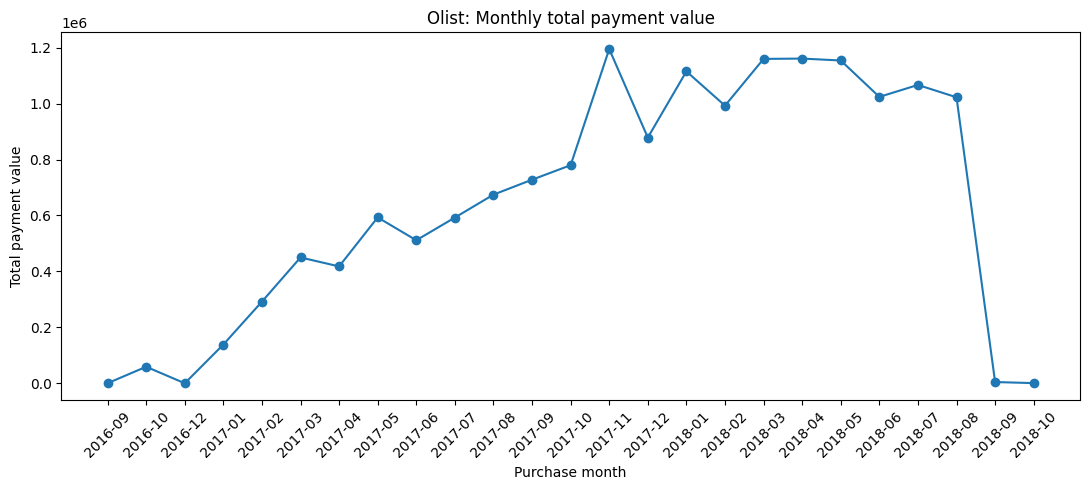

In [20]:
olist["purchase_month"] = (
    olist["order_purchase_timestamp"].dt.to_period("M").astype(str)
)

monthly_sales = (
    olist.groupby("purchase_month")["payment_value"]
    .sum()
    .sort_index()
)

display(monthly_sales.to_frame("total_payment_value"))
print("월별 결제액이 가장 큰 월:", monthly_sales.idxmax())
print("최대 월별 결제액:", round(monthly_sales.max(), 2))

plt.figure(figsize=(11, 5))
plt.plot(monthly_sales.index, monthly_sales.values, marker="o")
plt.title("Olist: Monthly total payment value")
plt.xlabel("Purchase month")
plt.ylabel("Total payment value")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

### 해석 및 인사이트
보고서에서는 가장 큰 월별 결제액이 2017년 11월의 1,194,882.80으로 나타났다. 2018년 마지막 일부 월의 값은 다른 달보다 매우 작다. 이는 데이터 수집 기간의 끝부분에 해당 월 데이터가 완전하게 포함되지 않았을 가능성이 있으므로, 마지막 월의 감소를 실제 시장 수요 감소라고 단정할 수 없다.

## 2.6 주(State)별 주문 건수 및 총 결제액

고객 거주 주(customer_state)를 기준으로 주문 건수와 총 결제액을 집계하고, 결제액 상위 10개 주를 시각화한다.

,order_count,total_payment
customer_state,,
SP,41746,5998226.96
RJ,12852,2144379.69
MG,11635,1872257.26
RS,5466,890898.54
PR,5045,811156.38
SC,3637,623086.43
BA,3380,616645.82
DF,2140,355141.08
GO,2020,350092.31


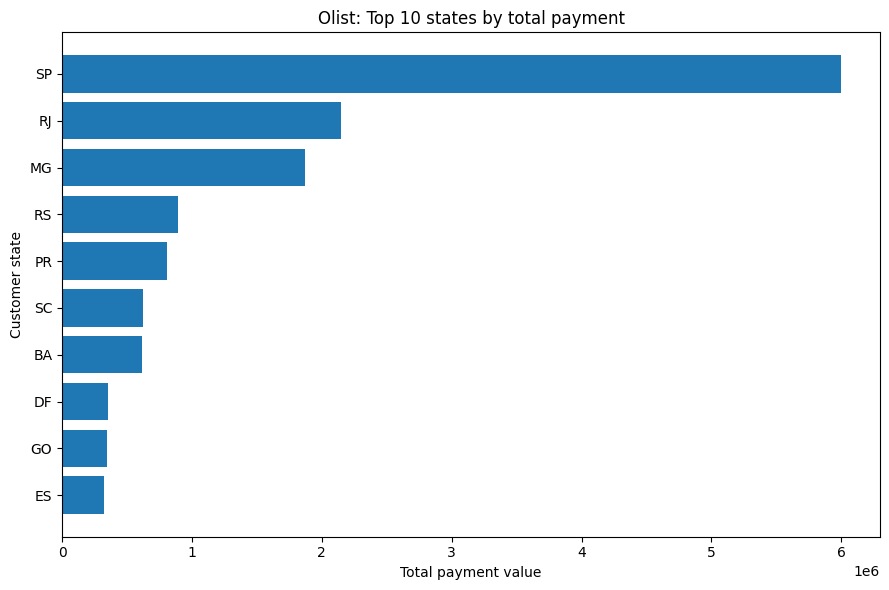

결제액 기준 상위 3개 주:


,order_count,total_payment
customer_state,,
SP,41746,5998226.96
RJ,12852,2144379.69
MG,11635,1872257.26


In [21]:
state_sales = (
    olist.groupby("customer_state")
    .agg(
        order_count=("order_id", "nunique"),
        total_payment=("payment_value", "sum")
    )
    .sort_values("total_payment", ascending=False)
)

display(state_sales.head(10))

top_states = state_sales.head(10).sort_values("total_payment")
plt.figure(figsize=(9, 6))
plt.barh(top_states.index, top_states["total_payment"])
plt.title("Olist: Top 10 states by total payment")
plt.xlabel("Total payment value")
plt.ylabel("Customer state")
plt.tight_layout()
plt.show()

print("결제액 기준 상위 3개 주:")
display(state_sales.head(3))

### 해석 및 인사이트
보고서 기준 결제액 상위 3개 주는 SP, RJ, MG이다. SP는 주문 41,746건, 총 결제액 5,998,226.96으로 가장 높은 값을 보였고, 다음은 RJ와 MG 순이다. 이는 고객 거주 주를 기준으로 집계한 결과이며 판매자 소재지 기준 매출과는 다를 수 있다.

## 2.7 배송 지연 여부와 리뷰 점수 비교

리뷰 테이블을 주문 데이터와 연결한다. 리뷰가 여러 개일 수 있으므로 주문별 평균 리뷰 점수를 계산한 뒤 병합하고, 실제 배송 완료 및 리뷰가 연결된 주문을 대상으로 배송 상태별 평균 점수를 비교한다.

,mean,count
delivery_status,,
Delayed,2.566562,7662
On time / early,4.294151,88168


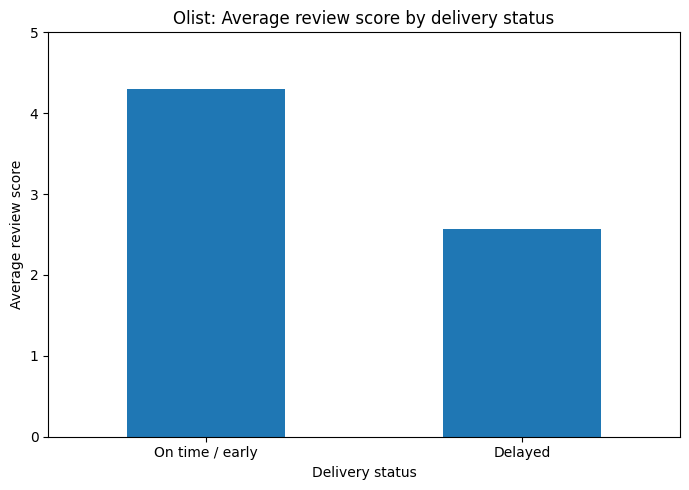

In [22]:
review_by_order = (
    reviews.groupby("order_id", as_index=False)["review_score"]
    .mean()
)

delivery_review = olist.merge(
    review_by_order, on="order_id", how="left"
)

valid_delivery_review = delivery_review.dropna(
    subset=["order_delivered_customer_date", "review_score", "delayed"]
).copy()

valid_delivery_review["delivery_status"] = np.where(
    valid_delivery_review["delayed"],
    "Delayed",
    "On time / early"
)

review_summary = (
    valid_delivery_review.groupby("delivery_status")["review_score"]
    .agg(["mean", "count"])
)

display(review_summary)

plt.figure(figsize=(7, 5))
review_summary["mean"].reindex(
    ["On time / early", "Delayed"]
).plot(kind="bar")
plt.title("Olist: Average review score by delivery status")
plt.xlabel("Delivery status")
plt.ylabel("Average review score")
plt.xticks(rotation=0)
plt.ylim(0, 5)
plt.tight_layout()
plt.show()

### 해석 및 인사이트
보고서에서는 실제 배송 완료 및 리뷰가 연결된 95,824건을 대상으로 비교했다. 정시 또는 예상일 이전 배송 그룹의 평균 리뷰 점수는 4.29점(88,163건), 지연 배송 그룹은 2.57점(7,661건)이다. 지연 배송 그룹의 평균 점수가 더 낮아 배송 지연과 고객 만족도 사이에 부정적인 연관성이 관찰된다. 다만 관찰 자료의 비교이므로 배송 지연이 낮은 리뷰 점수의 유일한 원인이라고 단정할 수 없다.

# 3. 종합 결론 및 분석의 한계

Spotify 분석에서는 인기도 80 이상인 트랙이 65개 장르에 분포했으며, pop, dance, rock 계열에서 해당 트랙 행이 상대적으로 많이 관찰되었다. valence와 popularity의 상관계수는 약한 음의 값으로, 곡의 밝기와 인기도 사이의 선형 관계는 거의 없었다.

Olist 분석에서는 고객 거주 주 기준으로 SP의 주문 건수와 결제액이 가장 컸으며, 배송 지연 그룹의 평균 리뷰 점수가 정시/조기 배송 그룹보다 낮았다. 이는 배송 경험이 고객 평가와 관련될 수 있음을 시사한다.

분석의 한계로는 Spotify 데이터의 장르 레이블 중복 가능성, Olist 데이터의 일부 결측 배송일, 월별 데이터의 마지막 기간 불완전 가능성, 그리고 상관관계 분석만으로 인과관계를 입증할 수 없다는 점이 있다. 따라서 결과는 제공된 데이터 범위 안에서 해석해야 한다.

## 4. 데이터 출처
- Spotify Songs Dataset: https://www.kaggle.com/datasets/maharshipandya/-spotify-tracks-dataset
- Brazilian E-Commerce Public Dataset by Olist: https://www.kaggle.com/datasets/olistbr/brazilian-ecommerce